In [1]:
import pandas as pd
books_df = pd.read_csv(r"C:\Users\LOQ\project_books\.venv\datas\books_dataset.csv")

In [2]:
books_df.head(10)

,google_id,title,subtitle,authors,publisher,published_date,description,categories,average_rating,ratings_count,page_count,language,isbn_10,isbn_13,thumbnail,search_category
0,_DYNAQAAMAAJ,The Face of Another,NaN,Kōbō Abe,Kodansha,1992,The Japanese novelist Kobo Abe has often been ...,Fiction,NaN,NaN,260.0,en,NaN,NaN,NaN,fiction
1,ggpgAAAAMAAJ,Generations of Winter,NaN,Василий Аксенов,Random House (NY),1994,"""Written in the great tradition of epic Russia...",Fiction,NaN,NaN,616.0,en,NaN,NaN,http://books.google.com/books/content?id=ggpgA...,fiction
2,v7VPEQAAQBAJ,The Street of Crocodiles,NaN,Bruno Schulz,Rare Treasure Editions,2025-03-19T00:00:00Z,''The Street of Crocodiles'' by Bruno Schulz (...,Fiction,NaN,NaN,136.0,en,808783027X,9.788088e+12,http://books.google.com/books/content?id=v7VPE...,fiction
3,FSTRAgAAQBAJ,Kokoro,Hints and Echoes of Japanese Inner Life,Lafcadio Hearn,Tuttle Publishing,2012-12-20,The 15 classic essays collected in Kokoro exam...,Literary Collections,NaN,NaN,267.0,en,1462900259,9.781463e+12,http://books.google.com/books/content?id=FSTRA...,fiction
4,qvk6DwAAQBAJ,Sense and Sensibility - Illustrated Edition,NaN,Jane Austen,Abela Publishing Ltd,2017-10-23,SENSE AND SENSIBILITY written by Jane Austen w...,Fiction,NaN,NaN,579.0,en,8826096473,9.788826e+12,http://books.google.com/books/content?id=qvk6D...,fiction
5,XUtNEQAAQBAJ,The Final Problem,NaN,Arthur Conan Doyle,SAMPI Books,2025-03-08,"In ""The Final Problem"", Sherlock Holmes finds ...",Fiction,NaN,NaN,39.0,en,6561335856,9.786561e+12,http://books.google.com/books/content?id=XUtNE...,fiction
6,l4MZAAAAYAAJ,A House-boat on the Styx,NaN,John Kendrick Bangs,NaN,1898,The premise of the book is that everyone who h...,Fiction,NaN,NaN,238.0,en,NaN,NaN,http://books.google.com/books/content?id=l4MZA...,fiction
7,b74fEAAAQBAJ,Jane Eyre,NaN,Charlotte Bronte,Principis,2021-03-10,"Mistério, traição, escândalo e um amor que tra...",Fiction,NaN,NaN,609.0,pt-BR,6555523689,9.786556e+12,http://books.google.com/books/content?id=b74fE...,fiction
8,Rf2dEAAAQBAJ,Virgin Soil,in large print,Ivan Sergeevich Turgenev,BoD – Books on Demand,2022-11-25,Reproduction of the original.,Fiction,NaN,NaN,429.0,en,3368437054,9.783368e+12,http://books.google.com/books/content?id=Rf2dE...,fiction
9,69JaAAAAMAAJ,Hemingway,A Life Without Consequences,James R. Mellow,NaN,1992,"Summary: A biography of the legendary writer, ...",Biography & Autobiography,NaN,NaN,742.0,en,NaN,NaN,http://books.google.com/books/content?id=69JaA...,fiction


In [3]:
print("ISBN-10 available:", books_df["isbn_10"].notna().sum())
print("ISBN-13 available:", books_df["isbn_13"].notna().sum())

ISBN-10 available: 4941
ISBN-13 available: 5175


In [4]:
top_books = books_df.sort_values(
    "ratings_count",
    ascending=False
)[[
    "title",
    "authors",
    "average_rating",
    "ratings_count"
]]

print(top_books.head(50).to_string(index=False))

                                                                                    title                      authors  average_rating  ratings_count
                                                    Mockingjay (Hunger Games, Book Three)              Suzanne Collins             4.0         2407.0
                                                                 The Hunger Games Trilogy              Suzanne Collins             4.0         1408.0
                                                                        The Da Vinci Code                    Dan Brown             4.0          693.0
                                                                      Fifty Shades Darker                    E L James             4.5          463.0
                                                                                Moby Dick              Herman Melville             4.0          274.0
                                                                            The Outsiders           

In [5]:
test_titles = [
    "The Great Gatsby",
    "1984",
    "The Hobbit",
    "Dune",
    "Pride and Prejudice",
    "To Kill a Mockingbird",
    "The Catcher in the Rye",
    "The Lord of the Rings",
    "Harry Potter",
    "The Hunger Games",
    "The Song of Achillies",
    "Foundation"
    "Harry potter and the philosopher's stone"
]

for title in test_titles:
    exists = books_df["title"].fillna("").str.lower().eq(title.lower()).any()

    print(f"{title}: {'FOUND' if exists else 'NOT FOUND'}")

The Great Gatsby: FOUND
1984: FOUND
The Hobbit: FOUND
Dune: FOUND
Pride and Prejudice: FOUND
To Kill a Mockingbird: FOUND
The Catcher in the Rye: FOUND
The Lord of the Rings: FOUND
Harry Potter: FOUND
The Hunger Games: FOUND
The Song of Achillies: NOT FOUND
FoundationHarry potter and the philosopher's stone: NOT FOUND


In [6]:
print(books_df[["title", "isbn_10", "isbn_13"]].head())

                                         title     isbn_10       isbn_13
0                          The Face of Another         NaN           NaN
1                        Generations of Winter         NaN           NaN
2                     The Street of Crocodiles  808783027X  9.788088e+12
3                                       Kokoro  1462900259  9.781463e+12
4  Sense and Sensibility - Illustrated Edition  8826096473  9.788826e+12


In [7]:
missing = books_df.isna().sum()

print(missing)

google_id             0
title                 0
subtitle           4861
authors             330
publisher          2966
published_date       67
description        1654
categories         1304
average_rating     6487
ratings_count      6487
page_count          309
language              0
isbn_10            2250
isbn_13            2016
thumbnail          1456
search_category       0
dtype: int64


In [9]:
missing = pd.DataFrame({
    "missing_count": books_df.isna().sum(),
    "missing_percentage": books_df.isna().mean() * 100
})

missing = missing.sort_values("missing_percentage", ascending=False)

display(missing.round(2))

,missing_count,missing_percentage
ratings_count,6487,90.21
average_rating,6487,90.21
subtitle,4861,67.60
publisher,2966,41.25
isbn_10,2250,31.29
isbn_13,2016,28.04
description,1654,23.00
thumbnail,1456,20.25
categories,1304,18.13
authors,330,4.59


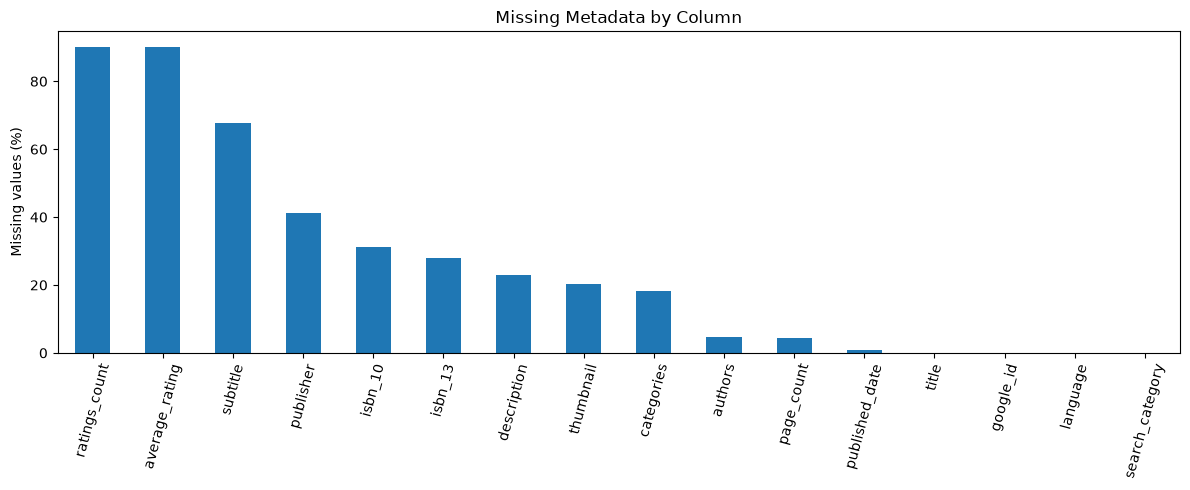

In [10]:
import matplotlib.pyplot as plt

missing["missing_percentage"].plot(
    kind="bar",
    figsize=(12, 5)
)

plt.ylabel("Missing values (%)")
plt.title("Missing Metadata by Column")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

In [8]:
print(books_df.columns)

Index(['google_id', 'title', 'subtitle', 'authors', 'publisher',
       'published_date', 'description', 'categories', 'average_rating',
       'ratings_count', 'page_count', 'language', 'isbn_10', 'isbn_13',
       'thumbnail', 'search_category'],
      dtype='str')
